# ¿Qué precio le pongo a mi auto usado?

Trabajo práctico de Python para Ciencia de Datos — UADE.

## 1. Pregunta y datos

Queremos estimar el precio de publicación, en dólares, de un auto usado según sus características. Es un problema de regresión porque la respuesta es un número. Cada fila representa un aviso histórico de Mercado Libre Argentina.

El dataset público fue publicado por Ariel Rasgido en Kaggle. La ficha conservada registra una actualización de febrero de 2024 y licencia declarada MIT. El archivo contiene 10.191 avisos y 25 columnas, con variables numéricas y categóricas. Trabajamos con usados publicados directamente en USD para comparar importes en la misma moneda. Los precios describen lo que pedían los vendedores en esa muestra histórica.

Leemos inicialmente las columnas como texto para revisar unidades y valores vacíos. La tabla de estado y moneda permite identificar las 4.047 filas del recorte. La comprobación SHA-256 verifica que usamos el mismo archivo documentado en el repositorio.

### Cómo ejecutar el trabajo

Descargá el repositorio completo y abrí este notebook desde la carpeta principal. Usá Python 3.12 e instalá las dependencias siguiendo el [README](README.md). Ejecutá todas las celdas en orden. El notebook necesita `src/autos.py`, los metadatos y el CSV incluidos en el repositorio.

El CSV incluido permite ejecutar el análisis sin conexión. Para recuperar el original, descargá el archivo desde la [fuente pública en Kaggle](https://www.kaggle.com/datasets/arielras/cars-publications-prices-mercadolibrearg) y copiá `MeliCarPublicactionsCSV/MeliCarPublicactions.csv` del ZIP a `data/raw/MeliCarPublicactions.csv`.


In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.autos import (
    ANIO_CORTE, ARCHIVO_FUENTE, CATEGORICAS, COLUMNAS_GRUPO, ETIQUETAS,
    NUMERICAS, PREDICTORAS, RESULTADOS, cargar, ejemplos, estimar, evaluar,
    guardar, limpiar, opciones, seleccionar, separar,
)

avisos_originales = cargar()
fuente = json.loads(ARCHIVO_FUENTE.read_text(encoding="utf-8"))
print("Cantidad de avisos", len(avisos_originales))
print("Cantidad de columnas", len(avisos_originales.columns))
print("Huella SHA 256 verificada", fuente["sha256"])
print("Tipos de columnas al leer", avisos_originales.dtypes.astype(str).value_counts().to_dict())

tabla_estado_y_moneda = pd.crosstab(
    avisos_originales["condition"], avisos_originales["currency"], margins=True
)
display(tabla_estado_y_moneda)

Cantidad de avisos 10191
Cantidad de columnas 25
Huella SHA 256 verificada 0bce5fcc04bc320713a750ebdf4512f35c638c96dcf6dedab8059e8bcc91f25f
Tipos de columnas al leer {'string': 25}


currency,ARS,USD,All
condition,,,
Nuevo,2072,57,2129
Usado,4015,4047,8062
All,6087,4104,10191


## 2. Limpieza de los avisos

Revisamos tipos, filas idénticas, identificadores repetidos, vacíos y valores imposibles. En el recorte de usados en USD conservamos la primera fila de cada identificador. Hay una inconsistencia entre el modelo Ford Ka y el título Focus III en un aviso repetido. Conservamos el modelo declarado y dejamos registrada esa limitación.

Convertimos los números escritos con unidades. Por ejemplo, 2.000 centímetros cúbicos equivalen a 2 litros. La expresión «4 cilindros» aporta otra característica, por lo que el motor queda como faltante. También convertimos a faltantes las especificaciones fuera de rango. Puertas y plazas deben ser enteros.

Excluimos precios inválidos, kilómetros negativos o inválidos y años fuera de 1886–2024 o con decimales. Registramos las 60.252 puertas del Corsa antes de excluirlo por su año 436673. Excluimos además un Fiat Uno cuyo título identifica USD 3.400 como anticipo. Las ofertas generales de financiación y los precios extremos que pasan los controles se conservan.

El recorte pasa de 4.047 a 4.044 avisos por un identificador duplicado, un año imposible y un anticipo. La auditoría muestra cantidades y motivos. La tabla de tipos y faltantes permite comprobar el resultado. La imputación de faltantes se ajusta posteriormente con los datos de entrenamiento.


In [2]:
print("Filas identicas repetidas", avisos_originales.duplicated().sum())
print("Identificadores repetidos", avisos_originales["id"].duplicated().sum())

vacios_por_columna = {}
for columna in avisos_originales.columns:
    textos = avisos_originales[columna].str.strip()
    cantidad = textos.eq("").sum()
    if cantidad > 0:
        vacios_por_columna[columna] = cantidad

vacios = pd.Series(vacios_por_columna, name="Vacíos en el CSV")
display(vacios.to_frame())

avisos, calidad = limpiar(avisos_originales)
assert avisos["id"].is_unique
assert avisos["price"].gt(0).all()
assert avisos["km"].ge(0).all()
assert avisos["car_year"].between(1886, ANIO_CORTE).all()

display(calidad.drop(columns="ids"))
columnas_a_revisar = ["price"] + PREDICTORAS
campos = avisos[columnas_a_revisar]
tabla_campos = pd.DataFrame({
    "Tipo tras la limpieza": campos.dtypes.astype(str),
    "Faltantes": campos.isna().sum(),
})
etiquetas_precio = ETIQUETAS.copy()
etiquetas_precio["price"] = "Precio (USD)"
display(tabla_campos.rename(index=etiquetas_precio))

Filas identicas repetidas 9
Identificadores repetidos 9


,Vacíos en el CSV
engine,254
engine_power,615
traction_control,317
passenger_capacity,595
transmission,241
seller_neighborhood,3774


,accion,motivo,cantidad
0,origen,Publicaciones en el CSV original,10191
1,fuera del alcance,Usados en ARS,4015
2,fuera del alcance,Publicaciones de vehículos nuevos,2129
3,selección,Usados publicados directamente en USD,4047
4,exclusión,ID de publicación repetido,1
5,normalización,Cilindrada recuperada de texto o unidades,23
6,normalización,Kilómetros convertido a número,4046
7,normalización,Potencia (hp) convertido a número,3786
8,corrección,Motor (L) imposible o no interpretable a faltante,6
9,corrección,Potencia (hp) imposible o no interpretable a f...,0


,Tipo tras la limpieza,Faltantes
Precio (USD),float64,0
Año,float64,0
Kilómetros,float64,0
Motor (L),float64,131
Potencia (hp),float64,260
Puertas,float64,0
Plazas,float64,222
Marca,object,0
Modelo,object,0
Combustible,object,0


## 3. Estadística descriptiva

Para las variables numéricas calculamos media, mediana, cuartiles y extremos. Para las categorías contamos valores diferentes y observamos cuál aparece con mayor frecuencia. Los histogramas muestran la distribución de precios y kilómetros. En los diagramas de caja, la caja contiene la mitad central de las observaciones.

En la muestra limpia, la mediana del precio es USD 8.700 y la media ronda USD 10.896. Los avisos de precios altos elevan la media. La mitad central de los precios está entre USD 6.100 y USD 13.000. Volkswagen es la marca con más avisos y Nafta es el combustible más frecuente.

Este análisis descriptivo utiliza toda la muestra limpia. El ajuste de las transformaciones y la selección de modelos de las secciones siguientes utilizan el conjunto de entrenamiento.


,Precio (USD),Año,Kilómetros,Motor (L),Potencia (hp),Puertas,Plazas
count,4044.00,4044.00,4044.00,3913.00,3784.00,4044.00,3822.00
mean,10896.21,2013.84,106858.90,1.67,120.01,4.31,4.98
std,7453.78,5.38,62226.86,0.37,38.01,0.76,0.26
min,1100.00,1990.00,500.00,1.00,49.00,2.00,2.00
25%,6100.00,2011.00,68000.00,1.40,92.00,4.00,5.00
50%,8700.00,2014.00,101000.00,1.60,110.00,4.00,5.00
75%,13000.00,2018.00,141000.00,2.00,143.00,5.00,5.00
max,82000.00,2024.00,999999.00,4.00,270.00,5.00,7.00


,Marca,Modelo,Combustible,Transmisión,Tracción
count,4044,4044,4044,3928,3905
unique,8,53,6,4,5
top,Volkswagen,Vento,Nafta,Manual,Delantera
freq,797,172,3418,3025,3551


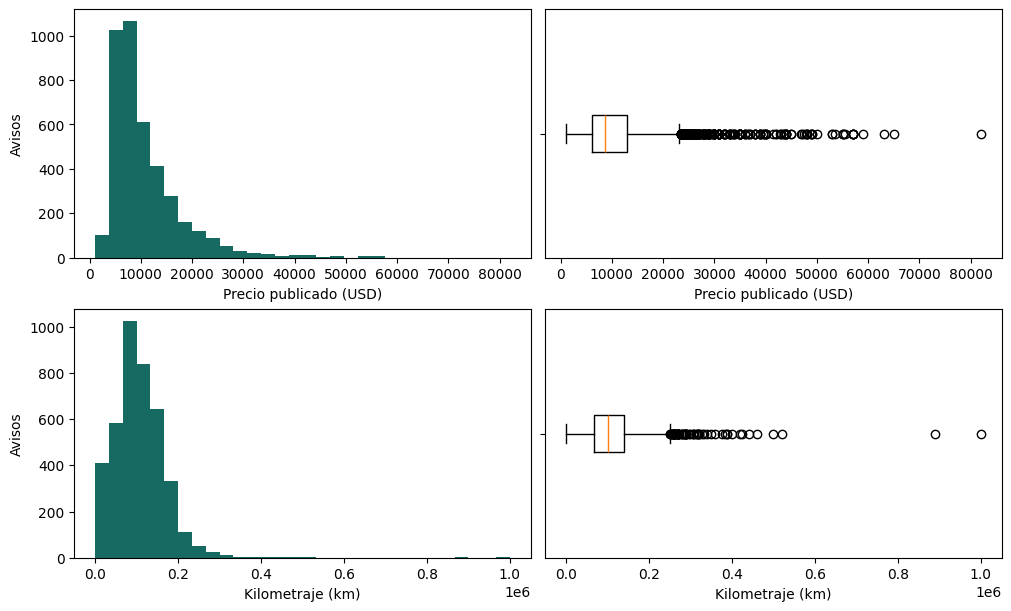

In [3]:
columnas_numericas = ["price"] + NUMERICAS
resumen_numerico = avisos[columnas_numericas].describe().round(2)
display(resumen_numerico.rename(columns=etiquetas_precio))
resumen_categorico = avisos[CATEGORICAS].describe()
display(resumen_categorico.rename(columns=ETIQUETAS))

RESULTADOS.mkdir(exist_ok=True)
figura, ejes = plt.subplots(2, 2, figsize=(10, 6), layout="constrained")

ejes[0, 0].hist(avisos["price"], bins=30, color="#166a62")
ejes[0, 0].set(xlabel="Precio publicado (USD)", ylabel="Avisos")
ejes[0, 1].boxplot(avisos["price"], orientation="horizontal", tick_labels=[""])
ejes[0, 1].set(xlabel="Precio publicado (USD)")

ejes[1, 0].hist(avisos["km"], bins=30, color="#166a62")
ejes[1, 0].set(xlabel="Kilometraje (km)", ylabel="Avisos")
ejes[1, 1].boxplot(avisos["km"], orientation="horizontal", tick_labels=[""])
ejes[1, 1].set(xlabel="Kilometraje (km)")

figura.savefig(RESULTADOS / "01_univariado.png", dpi=140)
plt.show()

## 4. Relación entre las características y el precio

Cada punto de los gráficos representa un aviso. Observamos cómo se relaciona el precio con el año y los kilómetros, y calculamos correlaciones numéricas con Pearson.

El precio tiene una asociación positiva con el año de fabricación, de aproximadamente 0,59, y negativa con el kilometraje, de aproximadamente −0,51. En esta muestra los autos más nuevos suelen publicarse a precios mayores y los de más kilómetros a precios menores. La dispersión muestra que esas características por separado dejan diferencias importantes por explicar.

Pearson resume la asociación lineal y puede verse afectado por valores extremos. Estas relaciones describen la muestra y requieren otras características para realizar una estimación individual.


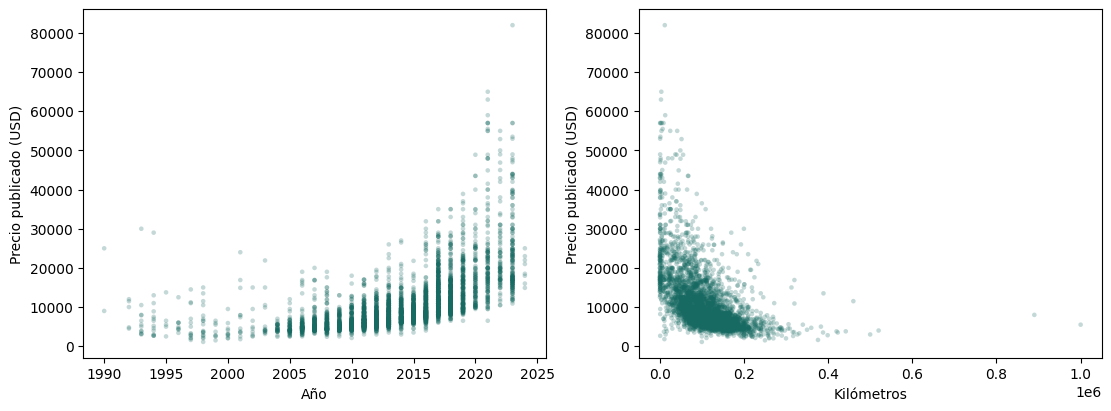

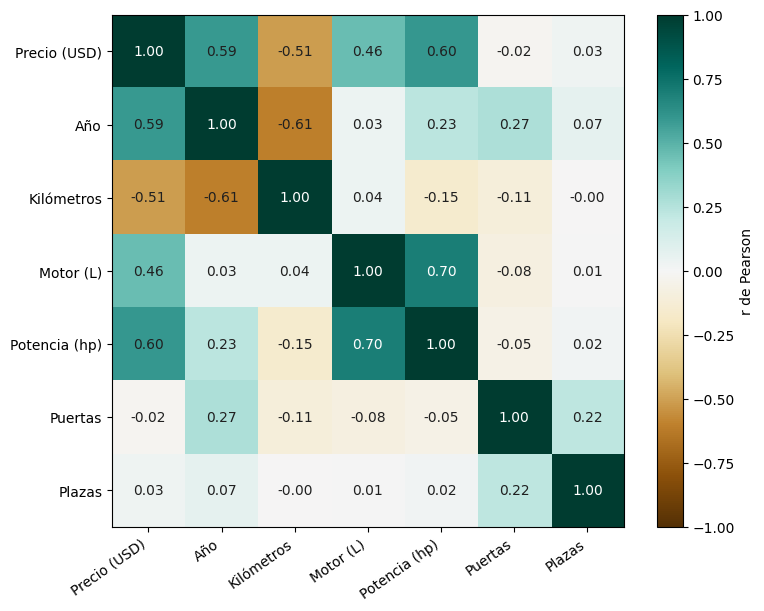

In [4]:
figura, ejes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")

ejes[0].scatter(avisos["car_year"], avisos["price"], alpha=0.25, s=11, color="#166a62", edgecolors="none")
ejes[0].set(xlabel=ETIQUETAS["car_year"], ylabel="Precio publicado (USD)")

ejes[1].scatter(avisos["km"], avisos["price"], alpha=0.25, s=11, color="#166a62", edgecolors="none")
ejes[1].set(xlabel=ETIQUETAS["km"], ylabel="Precio publicado (USD)")

figura.savefig(RESULTADOS / "02_relaciones.png", dpi=140)
plt.show()

numeros_con_etiquetas = avisos[columnas_numericas].rename(columns=etiquetas_precio)
correlaciones = numeros_con_etiquetas.corr()

figura, eje = plt.subplots(figsize=(8, 6), layout="constrained")
imagen = eje.imshow(correlaciones, vmin=-1, vmax=1, cmap="BrBG")
eje.set_xticks(range(len(correlaciones)), correlaciones.columns, rotation=35, ha="right")
eje.set_yticks(range(len(correlaciones)), correlaciones.index)

for fila in range(len(correlaciones)):
    for columna in range(len(correlaciones.columns)):
        valor = correlaciones.iloc[fila, columna]
        color = "#202020"
        if abs(valor) > 0.65:
            color = "white"
        eje.text(columna, fila, f"{valor:.2f}", ha="center", va="center", color=color)

figura.colorbar(imagen, ax=eje, label="r de Pearson")
figura.savefig(RESULTADOS / "03_correlacion.png", dpi=140)
plt.show()

Agrupamos por marca y por marca–modelo mediante `groupby` y `agg`. Para cada grupo calculamos cantidad, media y mediana del precio. El gráfico de barras compara las medianas por marca.

Toyota presenta la mayor mediana de esta muestra, USD 17.725, y Chevrolet la menor, USD 6.550. Cada marca reúne modelos, años y kilometrajes diferentes, por lo que la comparación también refleja esa composición. Los conteos ayudan a interpretar cuánto respaldo tiene cada resumen.

El CSV aporta el año de fabricación. Para construir una serie temporal de precios necesitaríamos fechas de publicación de los avisos. La fecha de actualización de Kaggle identifica la versión de los datos.


,n,media_usd,mediana_usd
brand,,,
Chevrolet,460,7542.00,6550.0
Fiat,480,9493.05,7000.0
Peugeot,750,8329.50,7000.0
Renault,390,9424.07,7800.0
Volkswagen,797,10219.35,9000.0
Ford,576,12071.26,10000.0
Honda,163,14247.64,12500.0
Toyota,428,20316.76,17725.0


n  media_usd  mediana_usd
brand      model                                 
Volkswagen Vento      172   15294.38      13500.0
Peugeot    307        166    6364.52       6000.0
           308        166   13106.96      10900.0
Volkswagen Bora       165    8774.28       8500.0
Honda      Civic      163   14247.64      12500.0
Peugeot    207        154    7227.91       6500.0
Volkswagen Gol        146    5475.37       5000.0
Peugeot    206        143    5279.92       4900.0
Renault    Clio       141    6194.16       6100.0
Volkswagen Gol Trend  139    8495.16       8200.0
Toyota     Etios      128   12841.09      12700.0
Ford       Ka         125    8352.97       8900.0

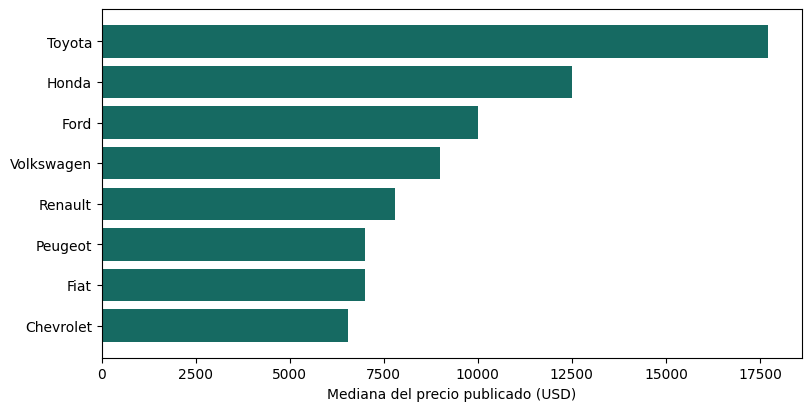

In [5]:
por_marca = avisos.groupby("brand").agg(
    n=("price", "size"),
    media_usd=("price", "mean"),
    mediana_usd=("price", "median"),
)
por_marca = por_marca.sort_values("mediana_usd")
display(por_marca.round(2))

por_marca_y_modelo = avisos.groupby(["brand", "model"]).agg(
    n=("price", "size"),
    media_usd=("price", "mean"),
    mediana_usd=("price", "median"),
)
por_marca_y_modelo = por_marca_y_modelo.sort_values("n", ascending=False)
display(por_marca_y_modelo.head(12).round(2))

figura, eje = plt.subplots(figsize=(8, 4), layout="constrained")
eje.barh(por_marca.index, por_marca["mediana_usd"], color="#166a62")
eje.set(xlabel="Mediana del precio publicado (USD)")
figura.savefig(RESULTADOS / "04_marcas.png", dpi=140)
plt.show()

## 5. Variables y separación

La variable objetivo `y` es el precio publicado en USD. Las entradas `X` reúnen seis variables numéricas y cinco categóricas. El identificador permite auditar filas y la versión sirve para agrupar. Excluimos el título de las entradas porque puede contener precios.

Formamos grupos con marca, modelo, versión y año. Así, los avisos con la misma configuración quedan juntos al separar entrenamiento y prueba. Reservamos aproximadamente un quinto de los grupos con semilla 42. El resultado es 3.213 avisos de entrenamiento y 831 de prueba.

Dentro de entrenamiento hacemos cinco rondas de validación con `GroupKFold`. Cada ronda ajusta con cuatro bloques de grupos y valida con el restante. Registramos los identificadores y comprobamos que ningún grupo aparezca a ambos lados de una separación.

La separación por grupos es una adaptación del método de validación visto en clase. La clave identifica configuraciones y puede dejar fichas con predictores iguales en grupos de distinta versión. Por eso verificamos también esas coincidencias y explicamos su alcance en los resultados.


In [6]:
nombres_predictores = []
for columna in PREDICTORAS:
    nombres_predictores.append(ETIQUETAS[columna])
print("Predictores", ", ".join(nombres_predictores))
print("Columnas del grupo", ", ".join(COLUMNAS_GRUPO))

particiones = separar(avisos)
predictores_entrenamiento = particiones.entrenamiento[PREDICTORAS]
precios_entrenamiento = particiones.entrenamiento["price"]
print("Cantidad de predictores", len(predictores_entrenamiento.columns))

detalle = particiones.detalle
tabla_particiones = pd.DataFrame({
    "publicaciones": [detalle["train"], detalle["test"]],
    "grupos": [detalle["grupos_train"], detalle["grupos_test"]],
}, index=["Entrenamiento", "Prueba"])
display(tabla_particiones)
print("Grupos compartidos", detalle["grupos_compartidos"])

tabla_rondas = pd.DataFrame(detalle["folds"])
display(tabla_rondas[["fold", "ajuste", "validacion", "grupos_compartidos"]])

Predictores Año, Kilómetros, Motor (L), Potencia (hp), Puertas, Plazas, Marca, Modelo, Combustible, Transmisión, Tracción
Columnas del grupo brand, model, version, car_year
Cantidad de predictores 11


,publicaciones,grupos
Entrenamiento,3213,1576
Prueba,831,394


Grupos compartidos 0


,fold,ajuste,validacion,grupos_compartidos
0,1,2573,640,0
1,2,2539,674,0
2,3,2579,634,0
3,4,2565,648,0
4,5,2596,617,0


## 6. Preparación y elección del modelo

Completamos los valores numéricos faltantes con la mediana. Después restamos la media y dividimos por el desvío estándar para comparar características con distintas unidades. Completamos las categorías faltantes con la moda.

Representamos las categorías mediante indicadores 0/1. Por ejemplo, una ficha con combustible Nafta activa la columna correspondiente. Esta codificación evita asignar un orden arbitrario a combustibles o marcas. Una categoría nueva deja en cero sus indicadores. Es una extensión de la conversión de categorías a números trabajada en clase.

El `Pipeline` aprende imputación, escala y categorías únicamente con los datos de ajuste de cada ronda. El modelo seleccionado vuelve a ajustarse con todo el entrenamiento antes de evaluar la prueba. `ColumnTransformer` permite aplicar una preparación a los números y otra a las categorías.

### Modelos comparados

Usamos como baseline la mediana de precios del conjunto de ajuste. La regresión lineal combina un valor inicial y los aportes de las columnas preparadas. k-NN busca fichas cercanas y promedia sus precios.

Probamos 5, 15 y 35 vecinos con pesos uniformes y por distancia. Con pesos por distancia, cada vecino aporta según el inverso de su distancia. Si existen coincidencias exactas, el promedio utiliza esas fichas. Ante distancias empatadas, usamos el orden de entrenamiento. La clase propia `VecinosRegresor` hace explícita esa regla para que Python y la herramienta HTML calculen de la misma manera.

### Elección mediante validación

`GridSearchCV` compara seis configuraciones de k-NN, además de regresión lineal y baseline. Elegimos el menor MAE promedio de las cinco rondas. Los valores internos de scikit-learn tienen signo negativo porque la búsqueda maximiza el puntaje.

La configuración elegida es k-NN con cinco vecinos ponderados por distancia. Su MAE de validación es USD 1.536,72. La decisión se toma con entrenamiento y validación, antes de calcular las métricas de prueba.


In [7]:
mediana_entrenamiento = precios_entrenamiento.median()
print(f"Referencia con la mediana del entrenamiento en USD {mediana_entrenamiento:,.2f}")

ganador, busquedas, validacion = seleccionar(particiones)
display(validacion.round(2))
print("Modelo con menor error de validacion", ganador)
print("Parametros elegidos", busquedas[ganador].best_params_)

Referencia con la mediana del entrenamiento en USD 8,500.00


,modelo,vecinos,pesos,MAE_CV,MAE_fold_1,MAE_fold_2,MAE_fold_3,MAE_fold_4,MAE_fold_5
0,k-NN,5.0,distance,1536.72,1401.30,1544.41,1470.76,1499.47,1767.69
1,k-NN,5.0,uniform,1558.04,1471.77,1651.82,1486.79,1398.96,1780.87
2,k-NN,15.0,distance,1576.87,1489.12,1585.89,1497.29,1499.19,1812.88
3,k-NN,35.0,distance,1640.96,1626.28,1640.05,1531.58,1532.53,1874.37
4,k-NN,15.0,uniform,1690.56,1709.87,1711.57,1639.11,1492.11,1900.13
5,k-NN,35.0,uniform,1804.71,1864.42,1868.64,1692.77,1575.08,2022.64
6,Regresión lineal,NaN,NaN,1985.46,1937.64,1913.68,1976.48,1853.30,2246.20
7,Baseline mediana,NaN,NaN,4610.23,4701.77,4936.99,4313.80,3981.20,5117.40


Modelo con menor error de validacion k-NN
Parametros elegidos {'modelo__n_neighbors': 5, 'modelo__weights': 'distance'}


## 7. Resultados y errores

Con el modelo elegido, comparamos las predicciones de prueba con los precios publicados. MAE es el error absoluto promedio en dólares. RMSE también se expresa en dólares y da más peso a los errores grandes. R² compara el error cuadrático con el de predecir la media observada de prueba. Nuestro baseline del experimento utiliza la mediana de entrenamiento.

k-NN obtiene MAE de USD 1.499,30, RMSE de USD 2.735,57 y R² de 0,9061. La regresión lineal obtiene MAE de USD 2.242,45 y el baseline USD 5.502,45. El mayor RMSE respecto del MAE indica que algunos errores son considerablemente más grandes que el promedio.

En el gráfico, los puntos sobre la diagonal serían predicciones exactas. Los puntos debajo representan estimaciones menores que el precio publicado.

Encontramos 14 fichas de prueba con los mismos predictores crudos que alguna de entrenamiento, aunque pertenecen a grupos de distinta versión. Los faltantes en los mismos campos cuentan como coincidencia. La clave de grupos permite controlar configuraciones repetidas, pero carecemos de un identificador del vehículo físico para descartar toda repetición entre avisos.


Fichas de prueba con predictores iguales a alguna de entrenamiento 14


,modelo,MAE_CV,MAE_test,RMSE_test,R2_test,elegido_por_CV
0,Baseline mediana,4610.23,5502.45,9523.42,-0.1384,False
1,Regresión lineal,1985.46,2242.45,4251.97,0.7731,False
2,k-NN,1536.72,1499.30,2735.57,0.9061,True


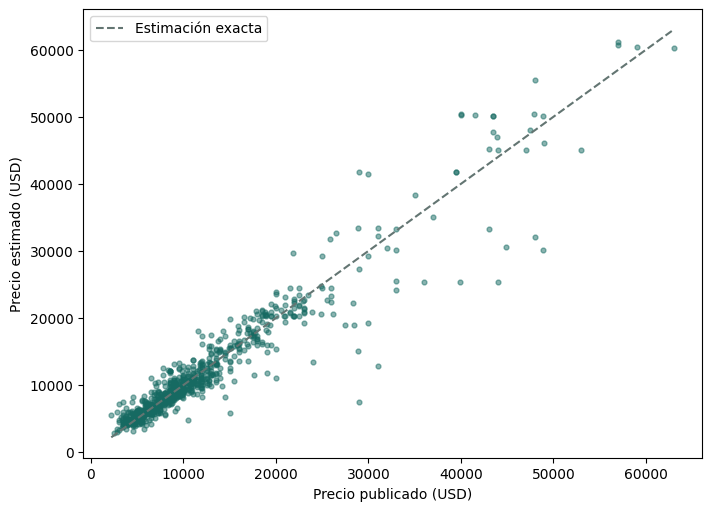

In [8]:
metricas, casos, segmentos, cortes = evaluar(particiones, ganador, busquedas)

predictores_sin_repetir = predictores_entrenamiento.drop_duplicates()
coincidencias = casos[PREDICTORAS].merge(predictores_sin_repetir, on=PREDICTORAS)
print("Fichas de prueba con predictores iguales a alguna de entrenamiento", len(coincidencias))
display(metricas.round({"MAE_CV": 2, "MAE_test": 2, "RMSE_test": 2, "R2_test": 4}))

figura, eje = plt.subplots(figsize=(7, 5), layout="constrained")
precio_minimo = min(casos["price"].min(), casos["precio_estimado"].min())
precio_maximo = max(casos["price"].max(), casos["precio_estimado"].max())
diagonal = [precio_minimo, precio_maximo]
eje.plot(diagonal, diagonal, color="#637572", linestyle="--", label="Estimación exacta")
eje.scatter(casos["price"], casos["precio_estimado"], alpha=0.5, s=12, color="#166a62")
eje.set(xlabel="Precio publicado (USD)", ylabel="Precio estimado (USD)")
eje.legend()
figura.savefig(RESULTADOS / "05_errores.png", dpi=140)
plt.show()

Desglosamos el error por marca, antigüedad y nivel de precio. La antigüedad usa 2024 como referencia y los niveles de precio usan terciles calculados en entrenamiento. El sesgo promedia «estimado menos publicado». Un sesgo negativo indica subestimación promedio.

El tramo de precios altos presenta el mayor MAE, aproximadamente USD 2.659 con 292 avisos de prueba. También mostramos un caso próximo al error mediano y los dos de mayor error para observar ejemplos concretos. El Fiat Uno 1994 publicado a USD 29.000 es el caso más alejado de la estimación. El dataset no permite determinar si su precio corresponde a una particularidad del auto o a un error del aviso.


In [9]:
print(f"Cortes de precio en entrenamiento en USD {cortes[0]:,.2f} y USD {cortes[1]:,.2f}")
display(segmentos.round(2))

error_mediano = casos["error_abs"].median()
distancia_a_la_mediana = (casos["error_abs"] - error_mediano).abs()
indice_tipico = distancia_a_la_mediana.idxmin()
caso_tipico = casos.loc[[indice_tipico]]
casos_mayores = casos.nlargest(2, "error_abs")
destacados = pd.concat([caso_tipico, casos_mayores])
columnas_destacadas = ["id", "brand", "model", "car_year", "price", "precio_estimado", "error"]
display(destacados[columnas_destacadas].round(2))

guardar(calidad, particiones, ganador, busquedas, validacion, metricas, casos, segmentos, cortes)

Cortes de precio en entrenamiento en USD 6,800.00 y USD 11,000.00


,variable,segmento,n,MAE,sesgo
0,brand,Chevrolet,104,739.15,-102.67
1,brand,Fiat,111,1436.93,47.55
2,brand,Ford,158,1768.56,235.03
3,brand,Honda,62,1529.96,-255.22
4,brand,Peugeot,102,1543.09,-448.95
5,brand,Renault,63,767.78,236.70
6,brand,Toyota,49,2952.06,1056.75
7,brand,Volkswagen,182,1565.06,-350.72
8,antiguedad,0 a 5 años,161,3054.73,-336.72
9,antiguedad,6 a 10 años,332,1215.62,-62.03


,id,brand,model,car_year,price,precio_estimado,error
711,MLA1620396722,Ford,Focus III,2015.0,10999.0,11826.13,827.13
550,MLA1654804436,Fiat,Uno,1994.0,29000.0,7516.73,-21483.27
653,MLA1400322295,Ford,Ranger Raptor,2020.0,48900.0,30180.09,-18719.91


## 8. Estimador y conclusiones

Probamos el estimador con tres avisos de entrenamiento elegidos por identificador. En la segunda ficha dejamos vacíos motor, potencia, puertas, plazas y tracción para mostrar cómo se completan con valores aprendidos. El formulario también verifica que el modelo pertenezca a la marca elegida.

Estas fichas sirven para demostrar el uso de la herramienta. Las métricas anteriores proceden de los 831 avisos reservados para prueba. La consola carga el modelo guardado y el HTML reproduce la preparación y el cálculo de vecinos para poder usarlo sin conexión.


In [10]:
opciones_ficha = opciones(particiones.entrenamiento)
modelo_elegido = busquedas[ganador].best_estimator_
demostracion = []

for ejemplo in ejemplos(particiones.entrenamiento):
    vehiculo = ejemplo["vehiculo"]
    cantidad_faltantes = len(PREDICTORAS) - len(vehiculo)
    precio_estimado = estimar(modelo_elegido, opciones_ficha, vehiculo)
    demostracion.append({
        "aviso_base": ejemplo["id"],
        "marca": vehiculo["brand"],
        "modelo": vehiculo["model"],
        "opcionales_faltantes": cantidad_faltantes,
        "estimacion_usd": precio_estimado,
    })

display(pd.DataFrame(demostracion).round(2))

,aviso_base,marca,modelo,opcionales_faltantes,estimacion_usd
0,MLA1402454175,Peugeot,307,0,16000.00
1,MLA1546276856,Volkswagen,Up!,5,7927.05
2,MLA1640255410,Ford,Focus III,0,13500.00


La muestra presenta precios concentrados en valores menores que su media y asociaciones entre precio, año y kilometraje. Comparar varias características mediante k-NN permitió reducir el MAE de prueba un 72,8 % frente a usar siempre la mediana de entrenamiento. Los errores son mayores en los autos de precios altos, y un promedio general puede ocultar casos muy alejados.

La herramienta ofrece una referencia sobre precios pedidos en avisos históricos. Para mejorarla, incorporaríamos estado del vehículo e historial de mantenimiento. Con fechas de publicación podríamos evaluar sobre avisos posteriores. Con precios de venta podríamos estudiar cuánto se pagó efectivamente. La cobertura de ocho marcas y los datos disponibles limitan la generalización a otros vehículos y al mercado actual.

La siguiente salida resume los resultados calculados por este notebook.


In [11]:
resultado_ganador = metricas.loc[metricas["elegido_por_CV"]].iloc[0]
resultado_mediana = metricas.loc[metricas["modelo"].eq("Baseline mediana")].iloc[0]
mae_ganador = resultado_ganador["MAE_test"]
mae_mediana = resultado_mediana["MAE_test"]
reduccion = 100 * (mae_mediana - mae_ganador) / mae_mediana

niveles = segmentos.loc[segmentos["variable"].eq("nivel_precio")]
tramo_mayor_error = niveles.loc[niveles["MAE"].idxmax()]
aviso_mayor_error = casos.loc[casos["error_abs"].idxmax()]
correlacion_anio = correlaciones.loc[ETIQUETAS["car_year"], "Precio (USD)"]
correlacion_km = correlaciones.loc[ETIQUETAS["km"], "Precio (USD)"]

print(f"Mediana del precio publicado en USD {avisos['price'].median():,.0f}")
print(f"Media del precio publicado en USD {avisos['price'].mean():,.0f}")
print(f"Correlacion con el año {correlacion_anio:.2f}")
print(f"Correlacion con los kilometros {correlacion_km:.2f}")
print()
print(f"Modelo elegido {ganador}")
print(f"MAE de prueba del modelo elegido en USD {mae_ganador:,.2f}")
print(f"MAE de prueba de la mediana en USD {mae_mediana:,.2f}")
print(f"Reduccion del error en porcentaje {reduccion:.1f}")
print()
print(f"Tramo con mayor error {tramo_mayor_error['segmento']}")
print(f"MAE del tramo en USD {tramo_mayor_error['MAE']:,.2f} con {tramo_mayor_error['n']} avisos")
print(
    "Aviso con mayor error",
    aviso_mayor_error["brand"],
    aviso_mayor_error["model"],
    int(aviso_mayor_error["car_year"]),
)
print(f"Precio publicado en USD {aviso_mayor_error['price']:,.0f}")
print(f"Precio estimado en USD {aviso_mayor_error['precio_estimado']:,.0f}")
print(f"Error absoluto en USD {aviso_mayor_error['error_abs']:,.0f}")

Mediana del precio publicado en USD 8,700
Media del precio publicado en USD 10,896
Correlacion con el año 0.59
Correlacion con los kilometros -0.51

Modelo elegido k-NN
MAE de prueba del modelo elegido en USD 1,499.30
MAE de prueba de la mediana en USD 5,502.45
Reduccion del error en porcentaje 72.8

Tramo con mayor error Alto
MAE del tramo en USD 2,659.07 con 292 avisos
Aviso con mayor error Fiat Uno 1994
Precio publicado en USD 29,000
Precio estimado en USD 7,517
Error absoluto en USD 21,483
